# Socio-Legal Studies Survey - Example Analysis



## 1 · Dependencies & configuration

In [25]:
import os
import pandas as pd
import pandasai as pai
from pandasai_litellm import LiteLLM
from dotenv import load_dotenv

load_dotenv()  # reads .env from the project root

LLM_BASE_URL = os.getenv("LLM_BASE_URL", "https://chat-ai.academiccloud.de/v1")
LLM_API_KEY  = os.environ["LLM_API_KEY"]
LLM_MODEL    = os.getenv("LLM_MODEL", "llama-3.3-70b-instruct")

# LiteLLM routes any OpenAI-compatible endpoint via the "openai/" model prefix.
llm = LiteLLM(
    model=f"openai/{LLM_MODEL}",
    api_key=LLM_API_KEY,
    api_base=LLM_BASE_URL,
)

pai.config.set({"llm": llm, "verbose": False, "save_charts": True})

## 2 · Load the survey data

In [26]:
import pandas as pd

# Column names are already sanitized to valid SQL/Python identifiers.
# Run `uv run python convert_data.py` to regenerate from the Excel source.
df = pd.read_csv("data/slt_raw_data.csv")
col_map = pd.read_csv("data/slt_column_mapping.csv").set_index("original_question")["column"]

# Convenience lookups for frequently used columns
COMMUNITY_COL = col_map["2. Which academic community are you part of?"]
GENDER_COL    = col_map["3. Are you"]
CAREER_COL    = col_map["6. What stage of your career do you see yourself being at?"]

print(f"Loaded {len(df):,} respondents x {len(df.columns)} columns")
df.head(2)

Loaded 139 respondents x 106 columns


,q1_i_confirm_that_i_agree,q2_which_academic_community_are_you,q2_a_if_you_selected_other_please,q3_are_you,q4_would_you_tell_us_your,q5_please_can_you_tell_us,q5_1_a_1_university,q5_1_b_1_year,q5_1_c_1_degree,q5_1_d_1_if_you_selected_other,...,q26_a_ii_what_are_the_target_audiences,q26_a_ii_a_if_you_selected_other_please,q27_do_you_mentor_and_or,q27_a_which_of_the_following_applies,q28_in_your_view_what_were,q29_where_would_you_like_socio,q30_i_d_like_to_receive,q30_a_please_fill_out_the_information,q30_b_name,q30_c_email
0,Yes,United Kingdom,NaN,male,46-55,NaN,LSE,2008.0,Ph.D / Dr.,NaN,...,Undergraduate Students,NaN,Yes,"I supervise undergraduate student theses,I sup...",I think the oxford centre for sociolegal studi...,Good Q. I don't really know. I'm not sure I wa...,Yes,I'd like to be informed about the results of t...,Ben Yong,benjamin.y.yong@durham.ac.uk
1,Yes,Germany,NaN,male,26-35,NaN,Technische Universität Dresden,2016.0,B.A.,NaN,...,NaN,NaN,No,NaN,NaN,NaN,No,NaN,NaN,NaN


### Column reference (first 10)

In [27]:
# Full mapping: sanitized column name -> original survey question
pd.read_csv("data/slt_column_mapping.csv")

,column,original_question
0,q1_i_confirm_that_i_agree,1. I confirm that I agree with the survey tool...
1,q2_which_academic_community_are_you,2. Which academic community are you part of?
2,q2_a_if_you_selected_other_please,"2.a. If you selected Other, please specify:"
3,q3_are_you,3. Are you
4,q4_would_you_tell_us_your,4. Would you tell us your age range?
...,...,...
101,q29_where_would_you_like_socio,29. Where would you like socio-legal studies t...
102,q30_i_d_like_to_receive,30. I'd like to receive information on the pro...
103,q30_a_please_fill_out_the_information,30.a. Please fill out the information below so...
104,q30_b_name,30.b. Name


## 3 · Set up PandasAI agent

We wrap the DataFrame in a `pai.DataFrame` and create an `Agent`.  
The agent remembers context across follow-up questions in the same session.

In [28]:
pai_df = pai.DataFrame(
    df,
    name="slt_survey",
    description=(
        "Socio-Legal Studies survey data (2021). "
        "139 respondents from Germany, the United Kingdom, and other countries. "
        "Covers academic identity, career stage, institutional affiliation, "
        "collaboration patterns, and publication strategies. "
        "Many columns contain NaN for unanswered questions. "
        "Always call .dropna() on a column before grouping, counting, or plotting it."
    ), # type: ignore
)

agent = pai.Agent([pai_df])

## 4 · Example queries

Each `agent.chat()` call returns the answer **and** logs the Python code
the LLM generated.  Set `verbose=True` (done in cell 1) to see it inline,
or call `agent.last_code_generated` after the query.

In [21]:
result = agent.chat("How many respondents are there in total?")
print(result)

2026-04-21 12:45:14 [INFO] Question: How many respondents are there in total?
2026-04-21 12:45:14 [INFO] Running PandasAI with litellm LLM...
2026-04-21 12:45:14 [INFO] Prompt ID: 7dea2fb8-b900-46d0-8008-c631830951c7
2026-04-21 12:45:14 [INFO] Generating new code...
2026-04-21 12:45:14 [INFO] Using Prompt: <tables>

<table dialect="duckdb" table_name="table_5f1b517d0098f606645dfa2f6a1a34fb" columns="[{"name": "q1_i_confirm_that_i_agree", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q2_which_academic_community_are_you", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q2_a_if_you_selected_other_please", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q3_are_you", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q4_would_you_tell_us_your", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q5_please_can_you_

In [22]:
result = agent.chat("What is the gender distribution of respondents?")
print(result)

2026-04-21 12:45:29 [INFO] Question: What is the gender distribution of respondents?
2026-04-21 12:45:30 [INFO] Running PandasAI with litellm LLM...
2026-04-21 12:45:30 [INFO] Prompt ID: 731810de-c4e1-42ce-8eaf-a4dbeafafcee
2026-04-21 12:45:30 [INFO] Generating new code...
2026-04-21 12:45:30 [INFO] Using Prompt: <tables>

<table dialect="duckdb" table_name="table_5f1b517d0098f606645dfa2f6a1a34fb" columns="[{"name": "q1_i_confirm_that_i_agree", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q2_which_academic_community_are_you", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q2_a_if_you_selected_other_please", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q3_are_you", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q4_would_you_tell_us_your", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q5_please_c

In [23]:
result = agent.chat("Which career stages are represented and how many respondents are at each stage?")
print(result)

2026-04-21 12:45:53 [INFO] Question: Which career stages are represented and how many respondents are at each stage?
2026-04-21 12:45:53 [INFO] Running PandasAI with litellm LLM...
2026-04-21 12:45:53 [INFO] Prompt ID: 7bc3c793-0f4b-48de-b660-9780e33c2722
2026-04-21 12:45:53 [INFO] Generating new code...
2026-04-21 12:45:54 [INFO] Using Prompt: <tables>

<table dialect="duckdb" table_name="table_5f1b517d0098f606645dfa2f6a1a34fb" columns="[{"name": "q1_i_confirm_that_i_agree", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q2_which_academic_community_are_you", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q2_a_if_you_selected_other_please", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q3_are_you", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q4_would_you_tell_us_your", "type": "string", "description": null, "expression": null, "alia

## 5 · Academic community breakdown

The column `2. Which academic community are you part of?` contains three values:
`Germany`, `United Kingdom`, and `Other`.

2026-04-21 12:48:45 [INFO] Question: Break down the number of respondents by the column 'q2_which_academic_community_are_you' and show the result as a bar chart.
2026-04-21 12:48:45 [INFO] Running PandasAI with litellm LLM...
2026-04-21 12:48:46 [INFO] Prompt ID: 80c86711-ea18-4177-aac1-e25839103c05
2026-04-21 12:48:46 [INFO] Generating new code...
2026-04-21 12:48:46 [INFO] Using Prompt: <tables>

<table dialect="duckdb" table_name="table_5f1b517d0098f606645dfa2f6a1a34fb" columns="[{"name": "q1_i_confirm_that_i_agree", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q2_which_academic_community_are_you", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q2_a_if_you_selected_other_please", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q3_are_you", "type": "string", "description": null, "expression": null, "alias": null}, {"name": "q4_would_you_tell_us_your", "type": "string", "

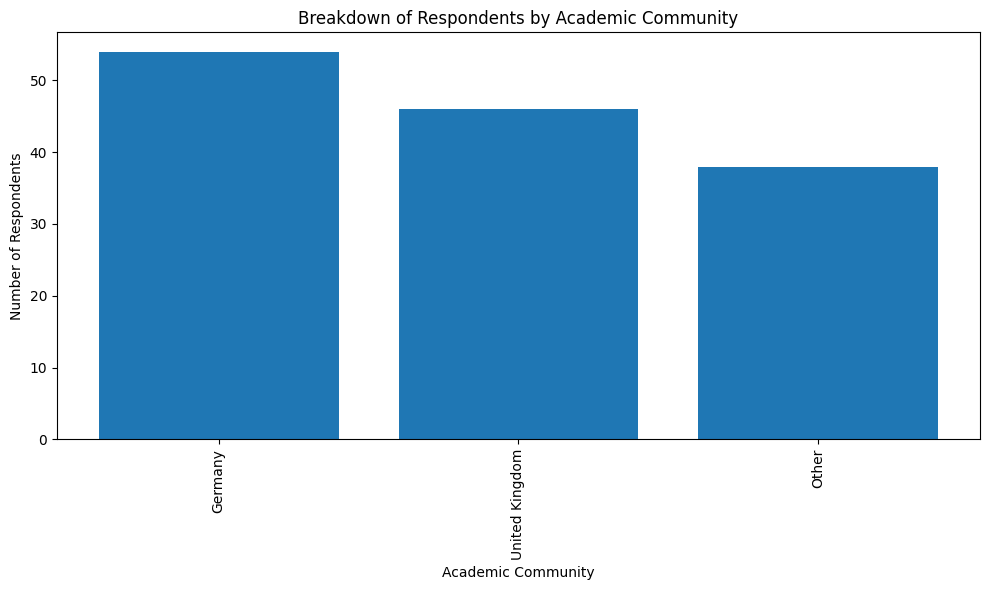

In [29]:
result = agent.chat(
    f"Break down the number of respondents by the column '{COMMUNITY_COL}' "
    "and show the result as a bar chart."
)
print(result)

### Reproducible code for the community breakdown

The cell below contains the Python code generated by the LLM for the query above,
extracted via `agent.last_code_generated`.  You can run it independently without
any LLM connection.

In [8]:
# Show the generated code so it can be copied / committed for reproducibility.
try:
    print(agent.last_code_generated)
except AttributeError:
    print("(last_code_generated not available in this version of PandasAI)")

(last_code_generated not available in this version of PandasAI)


### Standalone reproducible version (no LLM required)

In [ ]:
import matplotlib.pyplot as plt

COMMUNITY_COL = col_map["2. Which academic community are you part of?"]

counts = df[COMMUNITY_COL].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(counts.index, counts.values, color=["#4C72B0", "#DD8452", "#55A868"])
ax.bar_label(bars, padding=3, fontsize=11)
ax.set_title("Respondents by academic community", fontsize=13, pad=12)
ax.set_xlabel("Academic community")
ax.set_ylabel("Number of respondents")
ax.set_ylim(0, counts.max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("data/community_breakdown.png", dpi=150)
plt.show()

print("\nCounts:")
print(counts.to_string())
print(f"\nTotal: {counts.sum()}")

## 6 · Free-form exploration

Ask your own questions below.  The agent keeps session context,
so you can build on previous answers.

In [ ]:
# result = agent.chat("Your question here")
# print(result)